# B5 — Data Handling with Python: Reproducible Data Cleaning

This notebook turns three messy raw files into reliable, analysis-ready datasets.

| Raw file | Format | Content |
|---|---|---|
| `data/raw/orders.csv` | CSV | Online store orders |
| `data/raw/products.json` | JSON | Product catalogue |
| `data/raw/reviews.txt` | Text | Customer reviews (semi-structured) |

**Rules followed**
1. Raw files are **read only**, never modified.
2. Every cleaning decision is printed here and recorded in `docs/decision_log.md`.
3. Data is profiled **before** and **after** cleaning (`docs/data_profile.md`).
4. Running all cells top-to-bottom reproduces the cleaned files exactly.

> The dataset is **synthetic**, generated by `generate_raw_data.py` (fixed seed = 42).

## 1. Setup

In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd

# Works whether the notebook is run from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
CLEAN = ROOT / "data" / "cleaned"
DOCS = ROOT / "docs"
CLEAN.mkdir(parents=True, exist_ok=True)
DOCS.mkdir(parents=True, exist_ok=True)

MISSING_TOKENS = ["", "N/A", "null", "-", "NaN", "?"]
print("pandas", pd.__version__, "| raw folder:", RAW)

pandas 3.0.5 | raw folder: /home/claude/data/raw


## 2. Load raw data (read-only)

In [2]:
# Read everything as text first so nothing is silently converted
orders_raw = pd.read_csv(RAW / "orders.csv", dtype=str, keep_default_na=False)

with open(RAW / "products.json", encoding="utf-8") as f:
    catalogue = json.load(f)
products_raw = pd.json_normalize(catalogue["products"])

review_lines = (RAW / "reviews.txt").read_text(encoding="utf-8").splitlines()

print("orders:", orders_raw.shape, "| products:", products_raw.shape,
      "| review lines:", len(review_lines))
orders_raw.head()

orders: (473, 12) | products: (13, 7) | review lines: 206


,order_id,order_date,customer_id,customer_name,email,country,product_id,quantity,unit_price,total,payment_method,status
0,ORD-1379,2026-09-07,C053,TUNDE GARCIA,tunde.garcia53@example.com,ghana,P001,4,25.99,10.4,COD,Delivered
1,ORD-1230,2026-07-31,C035,Ahmed Garcia,ahmed.garcia35@example.com,Ghana,P008,1,59.99,59.99,paypal,delivered
2,ORD-1322,09-08-2026,C027,?,zara.rossi27@example.com,-,P009,4,29.9,119.6,CC,Delivered
3,ORD-1251,04-12-2026,C038,Ahmed Brown,ahmed.brown38@example.com,UK,P010,1,6.5,6.5,credit card,delivered
4,ORD-1119,2026-06-07,C001,Ahmed Adeyemi,ahmed.adeyemi1@example.com,Ghana,P011,1,99.0,99.0,paypal,Returned


## 3. Profile the raw data (BEFORE)

In [3]:
def profile(df, name):
    """One row per column: type, missing count (incl. placeholder tokens), uniques, examples."""
    rows = []
    for col in df.columns:
        s = df[col]
        as_text = s.astype(str).str.strip()
        missing = s.isna() | as_text.isin(MISSING_TOKENS + ["None", "nan", "<NA>", "NaT"])
        rows.append({
            "dataset": name,
            "column": col,
            "dtype": str(s.dtype),
            "missing": int(missing.sum()),
            "missing_%": round(missing.mean() * 100, 1),
            "unique": int(s.astype(str).nunique()),
            "examples": ", ".join(map(str, s.dropna().astype(str).unique()[:4])),
        })
    return pd.DataFrame(rows)

before_orders = profile(orders_raw, "orders (raw)")
before_products = profile(products_raw, "products (raw)")
before_orders

,dataset,column,dtype,missing,missing_%,unique,examples
0,orders (raw),order_id,str,0,0.0,450,"ORD-1379, ORD-1230, ORD-1322, ORD-1251"
1,orders (raw),order_date,str,22,4.7,350,"2026-09-07, 2026-07-31, 09-08-2026, 04-12-2026"
2,orders (raw),customer_id,str,0,0.0,60,"C053, C035, C027, C038"
3,orders (raw),customer_name,str,14,3.0,163,"TUNDE GARCIA, Ahmed Garcia , ?, Ahmed Brown"
4,orders (raw),email,str,28,5.9,77,"tunde.garcia53@example.com, ahmed.garcia35@exa..."
5,orders (raw),country,str,13,2.7,29,"ghana, Ghana, -, UK"
6,orders (raw),product_id,str,0,0.0,15,"P001, P008, P009, P010"
7,orders (raw),quantity,str,0,0.0,11,"4, 1, 3, 2"
8,orders (raw),unit_price,str,0,0.0,24,"25.99, 59.99, 29.9, 6.5"
9,orders (raw),total,str,0,0.0,87,"10.4, 59.99, 119.6, 6.5"


In [4]:
print("Exact duplicate order rows:", orders_raw.duplicated().sum())
print("Duplicate order_ids:", orders_raw["order_id"].duplicated().sum())
for col in ["country", "payment_method", "status"]:
    print(f"\n{col}: {orders_raw[col].nunique()} distinct spellings")
    print(sorted(orders_raw[col].unique()))

Exact duplicate order rows: 16
Duplicate order_ids: 23

country: 29 distinct spellings
['', '-', '?', 'England', 'GH', 'Ghana', 'KE', 'KENYA', 'Kenya', 'N/A', 'NG', 'NGA', 'NaN', 'Nigeria', 'Nigeria ', 'S. Africa', 'South Africa', 'U.K.', 'U.S.A', 'UK', 'US', 'USA', 'United Kingdom', 'United States', 'ZA', 'ghana', 'nigeria', 'south africa', 'united states']

payment_method: 24 distinct spellings
['', '-', '?', 'Bank Transfer', 'CASH', 'CC', 'COD', 'Card', 'Cash', 'Credit Card', 'Mobile Wallet', 'N/A', 'NaN', 'PayPal', 'Transfer ', 'bank transfer', 'card', 'cash on delivery', 'credit card', 'debit card', 'null', 'paypal', 'transfer', 'wallet']

status: 13 distinct spellings
['CANCELLED', 'Cancelled', 'DELIVERED', 'Delivered', 'Delivered ', 'In transit', 'Refunded', 'Returned', 'Shipped', 'canceled', 'delivered', 'returned', 'shipped']


In [5]:
before_products

,dataset,column,dtype,missing,missing_%,unique,examples
0,products (raw),product_id,str,0,0.0,12,"P001, P002, P003, P004"
1,products (raw),name,str,0,0.0,12,"Wireless Mouse, Mechanical Keyboard, USB-C Cab..."
2,products (raw),category,str,1,7.7,9,"Electronics, Accessories, Accesories, ELECTRONICS"
3,products (raw),price,object,1,7.7,12,"$25.99, 79.5, 9.99, 34.0"
4,products (raw),in_stock,object,0,0.0,5,"True, 0, False, yes"
5,products (raw),specs.weight_g,object,2,15.4,7,"1146, 2253, 915, unknown"
6,products (raw),specs.color,str,2,15.4,5,"Black, gray, grey, black"


In [6]:
# Reviews: what kinds of lines are there?
kinds = pd.Series([
    "blank" if not l.strip() else
    "comment" if l.startswith("#") else
    "junk" if l.startswith("ERROR") else "review"
    for l in review_lines]).value_counts()
print(kinds)
print("\nSample lines:")
print("\n".join(review_lines[3:10]))

review     193
blank        8
junk         3
comment      2
Name: count, dtype: int64

Sample lines:
08-15-2026 | ORD-1233 | ★ |    WASTE OF MONEY   
08-15-2026 | ORD-1233 | ★ |    WASTE OF MONEY   
2026-05-21 - ORD-1140 - three - It's okay.
ERROR: export timeout, retrying...
2026-04-22 | ord-1080 | ★★★★ | Nice, but delivery took long.
2026-06-04 ; ORD-1195 ; ★★★★★ ; Great value for money.
2026-08-31 | ORD-1329 | five | Great value for money.


## 4. Shared helper functions

In [7]:
def to_missing(s):
    """Strip whitespace and turn placeholder tokens ('N/A', '?', '-', ...) into real NaN."""
    s = s.astype(str).str.strip()
    return s.where(~s.isin(MISSING_TOKENS + ["None", "nan"]), np.nan)

DATE_FORMATS = [
    "%Y-%m-%d",        # 2026-03-04
    "%Y/%m/%d %H:%M",  # 2026/03/04 00:00
    "%d/%m/%Y",        # 04/03/2026  -> slash = DAY first (assumption, see decision log)
    "%m-%d-%Y",        # 03-04-2026  -> dash with year last = MONTH first
    "%B %d, %Y",       # March 04, 2026
    "%d %b %Y",        # 04 Mar 2026
]

def parse_date(value):
    """Try each known format; return NaT if none match (e.g. impossible dates)."""
    if pd.isna(value):
        return pd.NaT
    for fmt in DATE_FORMATS:
        try:
            return pd.to_datetime(value, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT

def to_number(s):
    """'$1,234.50' -> 1234.5 ; anything non-numeric -> NaN."""
    s = s.astype(str).str.replace(r"[$,\s]", "", regex=True)
    return pd.to_numeric(s, errors="coerce")

## 5. Clean `orders.csv`

In [8]:
log = []   # (step, rows affected, decision) -> becomes the decision log table
orders = orders_raw.copy()
n0 = len(orders)

# 5.1 Placeholder tokens -> NaN
before_na = orders.isna().sum().sum()
for col in orders.columns:
    orders[col] = to_missing(orders[col])
log.append(("Placeholders ('N/A','?','-','null','NaN','') to missing",
            int(orders.isna().sum().sum() - before_na), "Treated as missing, not as real values"))

# 5.2 Exact duplicates
dups = orders.duplicated().sum()
orders = orders.drop_duplicates()
log.append(("Drop exact duplicate rows", int(dups), "Identical rows are export repeats"))

# 5.3 Near-duplicates: same order_id, different details -> keep the first occurrence
near = orders["order_id"].duplicated().sum()
orders = orders.drop_duplicates(subset="order_id", keep="first")
log.append(("Drop repeated order_id (near-duplicates)", int(near),
            "order_id must be unique; first record kept"))
print(f"Rows: {n0} -> {len(orders)}")

Rows: 473 -> 450


In [9]:
# 5.4 Text standardisation
orders["customer_name"] = orders["customer_name"].str.title()

orders["email"] = orders["email"].str.lower()
bad_email = orders["email"].notna() & ~orders["email"].str.contains(r"^[^@\s]+@[^@\s]+\.[a-z]+$", regex=True, na=False)
orders.loc[bad_email, "email"] = np.nan
log.append(("Invalid emails (no '@') set to missing", int(bad_email.sum()),
            "Cannot be repaired reliably; not guessed"))

COUNTRY_MAP = {
    "nigeria": "Nigeria", "ng": "Nigeria", "nga": "Nigeria",
    "ghana": "Ghana", "gh": "Ghana",
    "kenya": "Kenya", "ke": "Kenya",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "u.k.": "United Kingdom", "england": "United Kingdom",
    "united states": "United States", "usa": "United States", "us": "United States", "u.s.a": "United States",
    "south africa": "South Africa", "za": "South Africa", "s. africa": "South Africa",
}
PAYMENT_MAP = {
    "card": "Card", "credit card": "Card", "cc": "Card", "debit card": "Card",
    "bank transfer": "Bank Transfer", "transfer": "Bank Transfer",
    "cash": "Cash on Delivery", "cash on delivery": "Cash on Delivery", "cod": "Cash on Delivery",
    "mobile wallet": "Mobile Wallet", "wallet": "Mobile Wallet", "paypal": "Mobile Wallet",
}
STATUS_MAP = {
    "delivered": "Delivered", "shipped": "Shipped", "in transit": "Shipped",
    "cancelled": "Cancelled", "canceled": "Cancelled",
    "returned": "Returned", "refunded": "Returned",
}
for col, mapping in [("country", COUNTRY_MAP), ("payment_method", PAYMENT_MAP), ("status", STATUS_MAP)]:
    before = orders[col].nunique()
    orders[col] = orders[col].str.lower().str.strip().map(mapping).where(orders[col].notna())
    log.append((f"Standardise {col}", f"{before} -> {orders[col].nunique()} categories",
                "Spelling/case/abbreviation variants mapped to one label"))

orders["product_id"] = orders["product_id"].str.strip().str.upper()

In [10]:
# 5.5 Dates
parsed = orders["order_date"].apply(parse_date)
unparseable = orders["order_date"].notna() & parsed.isna()
print("Unparseable dates:", orders.loc[unparseable, "order_date"].unique())
orders["order_date"] = parsed
log.append(("Parse 6 mixed date formats to YYYY-MM-DD", int(orders["order_date"].notna().sum()),
            "Slash dates read as DD/MM/YYYY, dash dates with year last as MM-DD-YYYY"))
log.append(("Impossible dates (e.g. 2027-02-30) set to missing", int(unparseable.sum()),
            "Not a real calendar date"))

Unparseable dates: <StringArray>
['2027-02-30']
Length: 1, dtype: str


In [11]:
# 5.6 Quantity
WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}
def parse_qty(v):
    if pd.isna(v):
        return np.nan
    v = str(v).strip().lower()
    if v in WORDS:
        return WORDS[v]
    m = re.match(r"^(-?\d+)", v)          # '3pcs' -> 3
    return float(m.group(1)) if m else np.nan

orders["quantity"] = orders["quantity"].apply(parse_qty)
invalid_qty = (orders["quantity"] <= 0) | (orders["quantity"] > 50)
print("Invalid quantities:", orders.loc[invalid_qty, "quantity"].tolist())
orders["quantity_flag"] = np.where(invalid_qty, "invalid (<=0 or >50)", "")
orders.loc[invalid_qty, "quantity"] = np.nan
orders["quantity"] = orders["quantity"].astype("Int64")
log.append(("Quantity words/units parsed ('two'->2, '3pcs'->3)", "-", "Recoverable, so converted"))
log.append(("Quantity <=0 or >50 (e.g. 999) set to missing + flagged", int(invalid_qty.sum()),
            "Impossible or extreme outlier; flagged instead of guessed"))

Invalid quantities: [0.0, -1.0, -1.0, -1.0, 0.0, 0.0, 999.0, -1.0, 0.0, 0.0, 0.0, 0.0, -1.0, 999.0, -1.0, -1.0, 0.0]


In [12]:
# 5.7 Prices and totals
orders["unit_price"] = to_number(orders["unit_price"])
orders["total_reported"] = to_number(orders["total"])
orders["total"] = (orders["quantity"].astype(float) * orders["unit_price"]).round(2)

mismatch = orders["total_reported"].notna() & orders["total"].notna() & \
           (orders["total_reported"] - orders["total"]).abs().gt(0.01)
orders["total_corrected"] = mismatch
log.append(("Strip '$' and ',' from unit_price", "-", "Convert to numeric"))
log.append(("Recompute total = quantity x unit_price", int(mismatch.sum()),
            "Reported totals that disagreed were replaced; original kept in total_reported"))

## 6. Clean `products.json`

In [13]:
products = products_raw.copy()
products["product_id"] = products["product_id"].str.strip().str.upper()
products["price"] = to_number(products["price"].astype(str))

# Conflicting duplicate (same product_id, different price): keep the first,
# whose price matches the prices actually charged in orders.csv
dup_p = products["product_id"].duplicated().sum()
products = products.drop_duplicates(subset="product_id", keep="first")
log.append(("Products: drop duplicate product_id with conflicting price", int(dup_p),
            "Kept the price that matches what orders were charged"))

CATEGORY_MAP = {"electronics": "Electronics", "electronic": "Electronics",
                "accessories": "Accessories", "accesories": "Accessories",
                "stationery": "Stationery", "stationary": "Stationery",
                "home office": "Home Office", "home-office": "Home Office", "homeoffice": "Home Office"}
products["category"] = products["category"].astype(str).str.strip().str.lower().map(CATEGORY_MAP)

# Missing category: P006 is 'Notebook A5' -> Stationery (from product name)
missing_cat = products["category"].isna()
products.loc[missing_cat & products["name"].str.contains("Notebook"), "category"] = "Stationery"
log.append(("Products: fill missing category from product name", int(missing_cat.sum()),
            "'Notebook A5' is clearly Stationery"))

# Missing price: use the unit price actually charged in orders
order_price = orders.groupby("product_id")["unit_price"].median()
missing_price = products["price"].isna()
products.loc[missing_price, "price"] = products.loc[missing_price, "product_id"].map(order_price)
log.append(("Products: fill missing price from median order unit_price", int(missing_price.sum()),
            "Orders show the real selling price"))

STOCK = {"true": True, "yes": True, "1": True, "false": False, "no": False, "0": False}
products["in_stock"] = products["in_stock"].astype(str).str.lower().map(STOCK)
products = products.rename(columns={"specs.weight_g": "weight_g", "specs.color": "color"})
products["weight_g"] = pd.to_numeric(products["weight_g"], errors="coerce")
products["color"] = products["color"].str.lower().replace({"gray": "grey"})
log.append(("Products: in_stock yes/no/1/0/True -> boolean; 'gray'->'grey'; weight 'unknown'->missing",
            "-", "One representation per value"))
products

,product_id,name,category,price,in_stock,weight_g,color
0,P001,Wireless Mouse,Electronics,25.99,True,1146.0,black
1,P002,Mechanical Keyboard,Electronics,79.50,False,2253.0,grey
2,P003,USB-C Cable 1m,Accessories,9.99,True,915.0,grey
3,P004,Laptop Stand,Accessories,34.00,False,NaN,black
4,P005,Noise-Cancelling Headphones,Electronics,149.00,True,NaN,grey
5,P006,Notebook A5 (pack of 3),Stationery,12.75,False,1398.0,black
6,P007,Desk Lamp LED,Home Office,42.00,True,NaN,black
7,P008,Webcam 1080p,Electronics,59.99,False,NaN,white
8,P009,Ergonomic Chair Cushion,Home Office,29.90,True,2384.0,NaN
9,P010,Ballpoint Pens (box of 12),Stationery,6.50,False,1205.0,black


In [14]:
# Cross-file check: orders that reference a product not in the catalogue
known = set(products["product_id"])
unknown = orders["product_id"].notna() & ~orders["product_id"].isin(known)
orders["unknown_product"] = unknown
print("Unknown product_ids in orders:", orders.loc[unknown, "product_id"].unique())
log.append(("Orders referencing unknown product_id flagged (not deleted)", int(unknown.sum()),
            "Keeps revenue data; flagged for follow-up"))

Unknown product_ids in orders: <StringArray>
['P099']
Length: 1, dtype: str


## 7. Clean `reviews.txt`

In [15]:
RATING_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}
def parse_rating(v):
    v = (v or "").strip().lower()
    if v.startswith("★"):
        return len(v)
    if v in RATING_WORDS:
        return RATING_WORDS[v]
    m = re.match(r"^(\d+)(?:\s*stars?|/5)?$", v)
    if m and 1 <= int(m.group(1)) <= 5:
        return int(m.group(1))
    return np.nan               # '', 'N/A', '10/10' (different scale) -> missing

records, skipped = [], {"blank": 0, "comment": 0, "junk": 0}
for line in review_lines:
    if not line.strip():
        skipped["blank"] += 1; continue
    if line.startswith("#"):
        skipped["comment"] += 1; continue
    if line.startswith("ERROR"):
        skipped["junk"] += 1; continue
    parts = re.split(r"\s*\|\s*|\s*;\s*|\t|\s+-\s+", line, maxsplit=3)
    if len(parts) != 4:
        skipped["junk"] += 1; continue
    date, oid, rating, comment = parts
    records.append({"review_date": parse_date(date.strip()),
                    "order_id": oid.strip().upper() or np.nan,
                    "rating": parse_rating(rating),
                    "comment": comment.strip()})

reviews = pd.DataFrame(records)
# ALL-CAPS comments -> sentence case
caps = reviews["comment"].str.isupper()
reviews.loc[caps, "comment"] = reviews.loc[caps, "comment"].str.capitalize()

dup_r = reviews.duplicated().sum()
reviews = reviews.drop_duplicates().reset_index(drop=True)
reviews["rating"] = reviews["rating"].astype("Int64")
reviews["order_found"] = reviews["order_id"].isin(set(orders["order_id"]))

print("Skipped lines:", skipped)
log.append(("Reviews: skip blank, header and 'ERROR' lines", sum(skipped.values()), "Not reviews"))
log.append(("Reviews: split on mixed separators ( | ; tab - )", len(records), "One parser for all formats"))
log.append(("Reviews: ratings '4/5','four','★★★★','4 stars' -> 1-5 integer",
            int(reviews["rating"].notna().sum()), "'10/10', 'N/A', blank -> missing (not guessed)"))
log.append(("Reviews: drop duplicate lines", int(dup_r), "Export repeats"))
log.append(("Reviews: lowercase order_ids upper-cased; ALL-CAPS comments sentence-cased",
            int(caps.sum()), "Consistent formatting"))
reviews.head(10)

Skipped lines: {'blank': 8, 'comment': 2, 'junk': 3}


,review_date,order_id,rating,comment,order_found
0,2026-08-15,ORD-1233,1,Waste of money,True
1,2026-05-21,ORD-1140,3,It's okay.,True
2,2026-04-22,ORD-1080,4,"Nice, but delivery took long.",True
3,2026-06-04,ORD-1195,5,Great value for money.,True
4,2026-08-31,ORD-1329,5,Great value for money.,True
5,2026-08-03,ORD-1012,4,"Works well, slightly overpriced.",True
6,2026-08-23,ORD-1179,5,"Excellent quality, arrived early!",True
7,2026-07-19,ORD-1293,5,"Excellent quality, arrived early!",True
8,2026-06-03,ORD-1313,3,It's okay.,True
9,2026-03-27,ORD-1223,4,"Good product, packaging was a bit damaged.",True


## 8. Final column order and export

In [16]:
orders = orders[["order_id", "order_date", "customer_id", "customer_name", "email", "country",
                 "product_id", "quantity", "unit_price", "total", "total_reported",
                 "payment_method", "status", "quantity_flag", "total_corrected",
                 "unknown_product"]].sort_values("order_id").reset_index(drop=True)
products = products[["product_id", "name", "category", "price", "in_stock",
                     "weight_g", "color"]].reset_index(drop=True)

orders.to_csv(CLEAN / "orders_clean.csv", index=False, date_format="%Y-%m-%d")
products.to_csv(CLEAN / "products_clean.csv", index=False)
reviews.to_csv(CLEAN / "reviews_clean.csv", index=False, date_format="%Y-%m-%d")
for f in sorted(CLEAN.glob("*.csv")):
    print(f.name, pd.read_csv(f).shape)

orders_clean.csv (450, 16)
products_clean.csv (12, 7)
reviews_clean.csv (180, 5)


## 9. Profile the cleaned data (AFTER) and compare

In [17]:
after_orders = profile(orders, "orders (clean)")
after_products = profile(products, "products (clean)")
after_reviews = profile(reviews, "reviews (clean)")

compare = before_orders[["column", "missing", "unique"]].merge(
    after_orders[["column", "dtype", "missing", "unique"]],
    on="column", how="outer", suffixes=("_before", "_after"))
compare

,column,missing_before,unique_before,dtype,missing_after,unique_after
0,country,13.0,29.0,str,12,6
1,customer_id,0.0,60.0,str,0,60
2,customer_name,14.0,163.0,str,13,52
3,email,28.0,77.0,str,39,60
4,order_date,22.0,350.0,datetime64[us],36,222
5,order_id,0.0,450.0,str,0,450
6,payment_method,25.0,24.0,str,24,4
7,product_id,0.0,15.0,str,0,13
8,quantity,0.0,11.0,Int64,17,5
9,quantity_flag,NaN,NaN,str,433,2


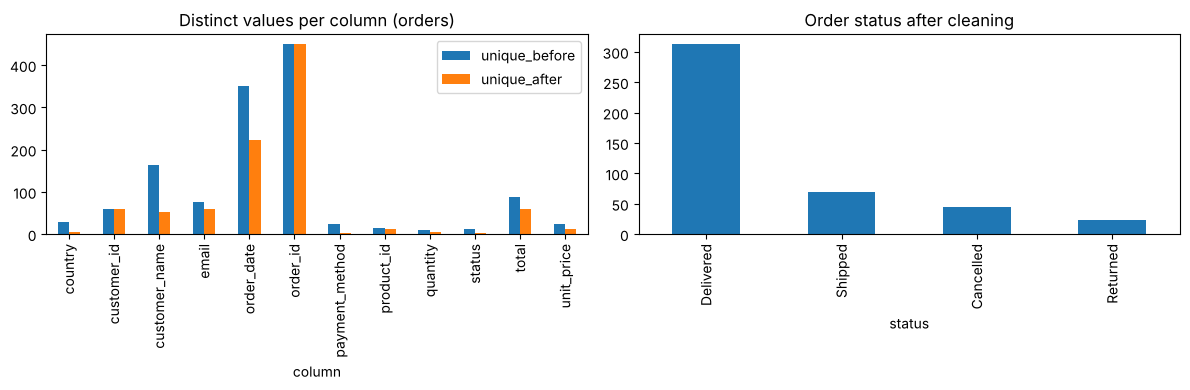

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
compare.set_index("column")[["unique_before", "unique_after"]].dropna().plot.bar(
    ax=axes[0], title="Distinct values per column (orders)")
orders["status"].value_counts().plot.bar(ax=axes[1], title="Order status after cleaning")
plt.tight_layout()
plt.show()

## 10. Save profile and decision log to `docs/`

In [19]:
decision_log = pd.DataFrame(log, columns=["step", "rows_affected", "decision / reason"])

with open(DOCS / "data_profile.md", "w", encoding="utf-8") as f:
    f.write("# Data profile — before and after cleaning\n\n")
    f.write("_Generated automatically by `notebooks/data_cleaning.ipynb`._\n\n")
    f.write(f"| | Raw | Clean |\n|---|---|---|\n")
    f.write(f"| Orders rows | {len(orders_raw)} | {len(orders)} |\n")
    f.write(f"| Products rows | {len(products_raw)} | {len(products)} |\n")
    f.write(f"| Review lines / rows | {len(review_lines)} | {len(reviews)} |\n\n")
    for title, df in [("Orders — before", before_orders), ("Orders — after", after_orders),
                      ("Products — before", before_products), ("Products — after", after_products),
                      ("Reviews — after", after_reviews)]:
        f.write(f"## {title}\n\n{df.drop(columns='dataset').to_markdown(index=False)}\n\n")

with open(DOCS / "transformation_log.md", "w", encoding="utf-8") as f:
    f.write("# Transformation log (generated)\n\n")
    f.write("_Every step below is produced by the notebook while it runs._\n\n")
    f.write(decision_log.to_markdown(index=False))

decision_log

,step,rows_affected,decision / reason
0,"Placeholders ('N/A','?','-','null','NaN','') t...",102,"Treated as missing, not as real values"
1,Drop exact duplicate rows,16,Identical rows are export repeats
2,Drop repeated order_id (near-duplicates),7,order_id must be unique; first record kept
3,Invalid emails (no '@') set to missing,12,Cannot be repaired reliably; not guessed
4,Standardise country,23 -> 6 categories,Spelling/case/abbreviation variants mapped to ...
5,Standardise payment_method,18 -> 4 categories,Spelling/case/abbreviation variants mapped to ...
6,Standardise status,12 -> 4 categories,Spelling/case/abbreviation variants mapped to ...
7,Parse 6 mixed date formats to YYYY-MM-DD,414,"Slash dates read as DD/MM/YYYY, dash dates wit..."
8,Impossible dates (e.g. 2027-02-30) set to missing,16,Not a real calendar date
9,"Quantity words/units parsed ('two'->2, '3pcs'->3)",-,"Recoverable, so converted"


## 11. Summary

- **Orders:** duplicates removed, 6 date formats unified, categories standardised, prices numeric,
  totals recomputed, impossible values flagged rather than guessed.
- **Products:** nested JSON flattened, conflicting duplicate resolved, missing values filled from evidence.
- **Reviews:** free-text lines parsed into a table with 1–5 ratings, junk and duplicate lines removed.

Limitations and trade-offs are discussed in `docs/decision_log.md`.